# Load the images + plant segmentations and overlay them

One repo, two configs:

| config | contents | download |
| --- | --- | --- |
| default | photos + metadata | ~1.3 GB |
| `segmentations` | same rows + plant masks, no images | ~32 MB |

Only rows **100–999** have masks (up to 9 plants per frame). Mask coordinates are in the
**undistorted 1920x1920** frame, so the image has to be de-fished before overlaying.

You need the Hugging Face token from Discord and access to the private dataset.

In [1]:
!uv pip install datasets huggingface_hub pillow defisheye matplotlib pandas "pycocotools>=2.0.10"

# OR
# !uv pip install datasets huggingface_hub pillow defisheye matplotlib pandas "pycocotools>=2.0.10"

Using Python 3.12.16 environment at: /workspaces/CanopyMap/.venv
Resolved 44 packages in 288ms                                        
Prepared 1 package in 94ms                                                   pycocotools          ------------------------------ 269.93 KiB/402.04 KiB       
Installed 1 package in 4ms                                  
Bytecode compiled 4 files in 52ms
 + pycocotools==2.0.11


In [2]:
import os
from huggingface_hub import login

login(token=os.environ.get("HF_TOKEN"))  # or paste the token from Discord

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Load both configs

`load_dataset` returns a `DatasetDict`; we keep the `train` split. The segmentations
config is small, so it loads in seconds. The image config is cached after the first run.

In [3]:
from datasets import load_dataset

DATASET = "regularpooria/canopymap_plants"

images = load_dataset(DATASET, split="train")  # photos
segs = load_dataset(DATASET, "segmentations", split="train")  # masks, row i == images row i

print(images)
print(segs)

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons'],
    num_rows: 3163
})
Dataset({
    features: ['channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons', 'frame_idx', 'seg_n_plants', 'seg_ids', 'seg_bboxes_xyxy', 'seg_areas', 'seg_rle'],
    num_rows: 3163
})


### What's in a segmentation row

| column | meaning |
| --- | --- |
| `frame_idx` | row index in the image config (0–3162) |
| `seg_n_plants` | number of tracked plants in this frame |
| `seg_ids` | plant ids, stable across frames |
| `seg_bboxes_xyxy` | boxes `[x1, y1, x2, y2]` in undistorted pixels |
| `seg_areas` | mask area in pixels |
| `seg_rle` | COCO compressed RLE per plant |

All lists are aligned positionally. The `ph_*` columns are plant-holder detections, not these masks.

In [4]:
row = segs[100]
print({k: (v if k != "seg_rle" else f"<{len(v)} masks>") for k, v in row.items()})

{'channel': 'channel5', 'date': '2026-05-17', 'time': '15:44:05', 'suitable': True, 'ph_boxes_xyxy': [[446.1000061035156, 1250.9000244140625, 566.0999755859375, 1375.300048828125], [931.0999755859375, 815.9000244140625, 1021.9000244140625, 887.0999755859375], [1182.0, 954.9000244140625, 1283.300048828125, 1042.4000244140625], [721.4000244140625, 1003.0999755859375, 820.7999877929688, 1097.0], [718.0999755859375, 1516.5999755859375, 855.5, 1677.800048828125], [22.799999237060547, 781.2999877929688, 103.0999984741211, 844.7999877929688], [1007.5999755859375, 1192.699951171875, 1109.699951171875, 1311.0999755859375], [731.0, 700.5, 811.9000244140625, 763.5], [521.2000122070312, 853.7999877929688, 612.2999877929688, 929.7999877929688], [243.8000030517578, 647.5, 317.8999938964844, 702.4000244140625], [434.3999938964844, 539.9000244140625, 501.20001220703125, 585.5999755859375], [261.5, 1048.699951171875, 363.0, 1139.4000244140625], [328.29998779296875, 481.70001220703125, 388.2999877929687

In [ ]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pycocotools import mask as mask_utils

root = Path.cwd().resolve()
while not (root / "src").exists():
    root = root.parent
sys.path.append(str(root))

from src.utils.distortion import de_fish_eye_image


def undistort(image):
    """De-fish a stored photo the same way the tracker did."""
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "frame.jpg"
        image.convert("RGB").save(path, quality=95)
        bgr = de_fish_eye_image(str(path))
    return bgr[..., ::-1]  # BGR -> RGB


def color_for(pid):
    """A fixed color per plant id."""
    r, g, b, _ = plt.cm.tab10(pid % 10)
    return np.uint8([r * 255, g * 255, b * 255])

In [6]:
def show(frame_idx, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 10))

    seg = segs[frame_idx]
    frame = undistort(images[frame_idx]["image"])

    overlay = np.zeros((*frame.shape[:2], 4), dtype=np.uint8)
    for pid, (x1, y1, _, _), rle in zip(seg["seg_ids"], seg["seg_bboxes_xyxy"], seg["seg_rle"]):
        mask = mask_utils.decode({"size": [1920, 1920], "counts": rle}).astype(bool)
        overlay[mask] = (*color_for(pid), 130)
        ax.text(x1 + 6, y1 + 20, str(pid), color="white", fontsize=11, weight="bold")

    ax.imshow(frame)
    ax.imshow(overlay)
    ax.set_title(
        f"frame {frame_idx} | {seg['channel']} | {seg['date']} {seg['time']} "
        f"| {seg['seg_n_plants']} plants",
        fontsize=10,
    )
    ax.axis("off")

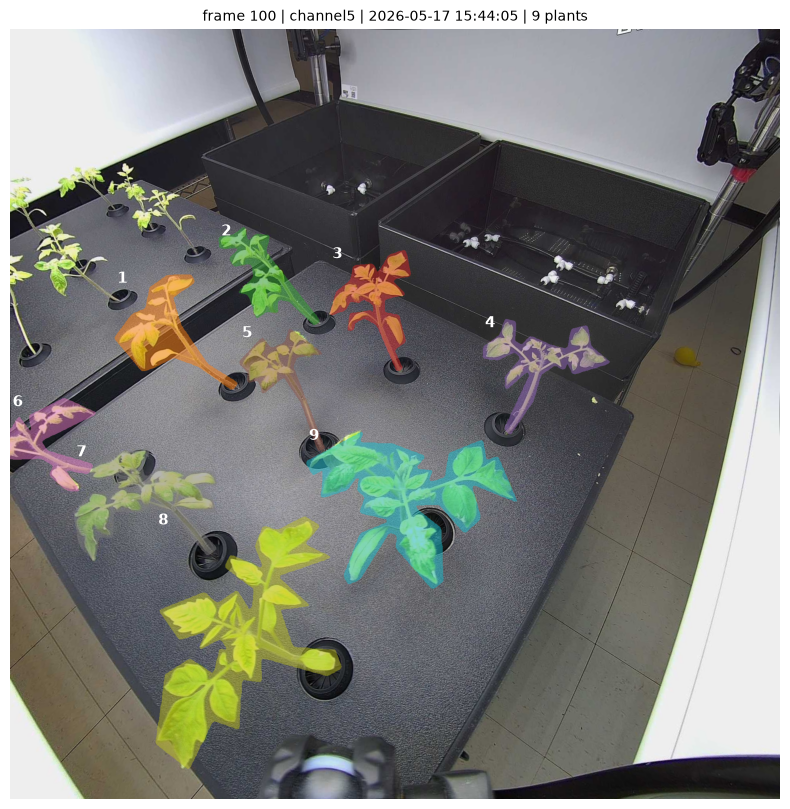

In [7]:
show(100)
plt.show()

### Why de-fish first

The stored photos are raw fisheye (2560x1920); the masks live in the undistorted 1920x1920
frame. Drawing the mask on the raw photo makes it look shifted, which is expected.

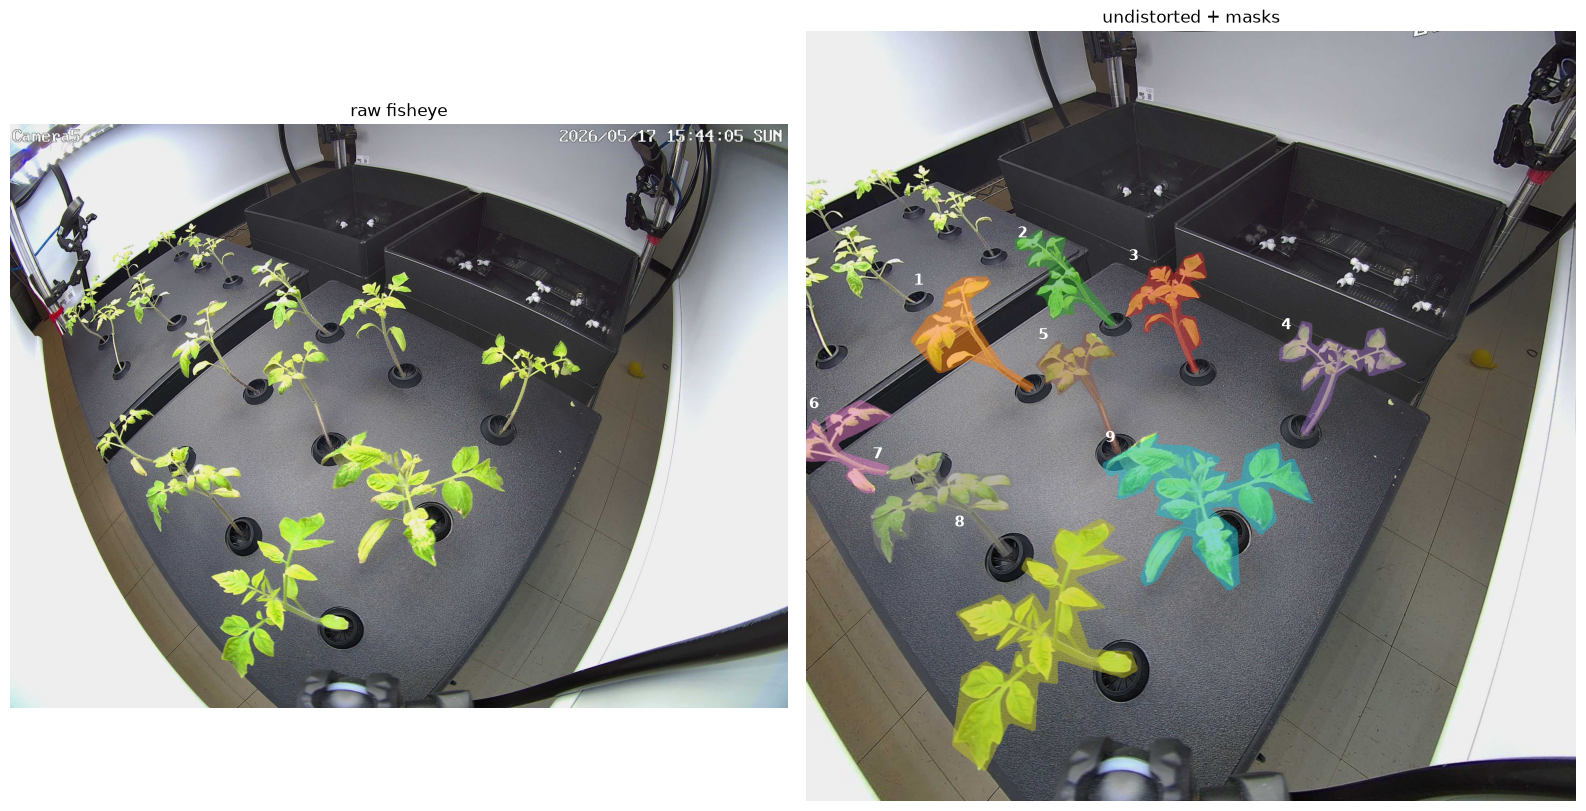

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(images[100]["image"])
axes[0].set_title("raw fisheye")
axes[0].axis("off")

show(100, ax=axes[1])
axes[1].set_title("undistorted + masks")
plt.tight_layout()
plt.show()

# PUT YOUR CODE HERE

## Probably some code to use the segmentation data to calculate area for each plant

## Some code to plot the area over time for each plant

If you want, instead of area, you can count the green pixels within the segmentation and plot that instead, keep both plots, it would be cool to see the difference